## Generate cell population data for figure 3 for all six conditions

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle

sys.path.insert(0, "./cellular_cycle")
sys.path.insert(0, "./figures")

import fracprolif as fp
from cell_cycle_death_model import model
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from model_fxns import *
from Cell_Population_Simulation import Cell_Population_Simulation
from SMs_G1s_IMTs_extraction import SMs_G1s_IMTs_extraction
from call_cell_events import call_events #
from retrieve_cellState_dw_2 import retrieve_cellState #

In [2]:
# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [3]:
# import pysb sampled parameters
sampled_parameter_names = np.loadtxt('model_data/sampled_parameter_names.txt', dtype=str)

In [4]:
# Importing the parameters:
new_param = pd.read_csv('test_treatments/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

Stress
b
Hippo_tot
Yap_tot
AKT_tot
ERK_tot
FAK_tot
skp2_tot
p21_tot
cdh1_tot
CycD_tot
K_1E2F
V_1E2F
k_cd4
k_myc1
k_CE
d_CE
K_i13
K_i14
V_sac
V_da
V_sec
V_de
V_sf
V_fs
V_dfa
v_scdh1a
v_2fak
v_s2p21
K_AFAK
K_dfa
K_fs
K_cf
K_cac
K_cec
K_da
K_de
K_sp21
k_dcdh1a
K_p21fak.1
k_CDF
K_DF
K_dcescp2


In [5]:
# Setting initial concentrations '/../model_data/initial_concentrations.csv'
initial_concentrations = pd.read_csv('model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

BAXm_0
BCL2_0


In [6]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv('model_data/ECM_conditions_2.csv')
ECM_conditions


,condition,stiffness,drug,species,value
0,55 kPa DMSO,55 kPa,DMSO,AKT,1.0
1,55 kPa DMSO,55 kPa,DMSO,ERK,1.0
2,55 kPa DMSO,55 kPa,DMSO,FAK,1.0
3,4 kPa DMSO,4 kPa,DMSO,AKT,1.0
4,4 kPa DMSO,4 kPa,DMSO,ERK,1.0
5,4 kPa DMSO,4 kPa,DMSO,FAK,0.6
6,0.6 kPa DMSO,0.6 kPa,DMSO,AKT,0.6
7,0.6 kPa DMSO,0.6 kPa,DMSO,ERK,1.0
8,0.6 kPa DMSO,0.6 kPa,DMSO,FAK,0.4
9,55 kPa erlotinib,55 kPa,erlotinib,AKT,0.6


<Axes: xlabel='Time (h)', ylabel='Concentration'>

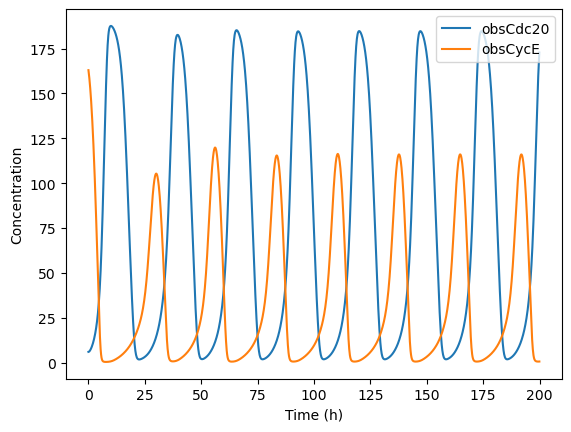

In [7]:
condition = "55 kPa erlotinib"

t = np.linspace(0, 20000, 200001)

model.parameters['AKT'].value = 0.6
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 1
# t = np.linspace(0, 50000, 500001)
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run() #deterministic simulation

observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,2000), legend=True)


<Axes: xlabel='Time (h)', ylabel='Concentration'>

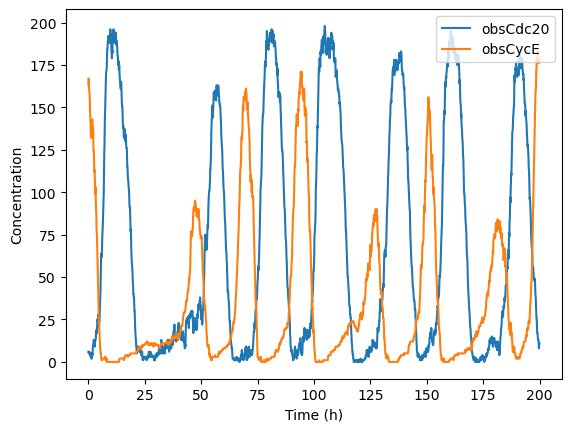

In [8]:
sim_stoch = BngSimulator(model, tspan=t, verbose=False)
sim_stoch_res = sim_stoch.run(method='ssa', verbose=False)
observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_stoch_res.all, obs=observables, times=t, tpos=range(0,2000), legend=True)


### Run example simulation
Use low stiffness and DMSO treatment as condition. Must use more cells to get decent output.

In [9]:
start_time = datetime.datetime.now()

init = 3
run_time = 120
observed_cells_time = 120
condition = "55 kPa erlotinib"

In [10]:
# Run the model
# Simulate Check_Model_Consistency
# (variable_range, check, tmp_score) = Check_Model_Consistency(model, thr=0.26, return_plot=True)

(check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
current_time = datetime.datetime.now()
print(f'elapsed time is {(current_time-start_time)/60} minutes')

55 kPa erlotinib
BAXm_0
BCL2_0
elapsed time is 0:00:00.571100 minutes


In [11]:
population_history = population_df
parameters_sim = {}

In [12]:
population_df

,Old ID,New ID,Lineage,Event,Start Time,Birth Time,End Time,Starting Cell,Lifetime
0,0,0,Initial cell,Mitosis,0.000000,Initial cell,0.000000,True,0.000000
1,0,62,0,Mitosis,0.000000,0,13.143813,False,13.143813
2,0,63,62,Apoptosis,13.143813,13.143813,41.638796,False,28.494983
3,1,1,Initial cell,Mitosis,0.000000,Initial cell,7.826087,True,7.826087
4,1,64,1,Mitosis,7.826087,7.826087,30.000000,False,22.173913
...,...,...,...,...,...,...,...,...,...
116,57,57,88,End of experiment,112.125409,112.125409,120.081939,False,7.956530
117,58,58,96,End of experiment,114.050471,114.050471,120.080209,False,6.029738
118,59,59,105,End of experiment,110.210162,110.210162,120.083882,False,9.873719
119,60,60,114,End of experiment,109.524519,109.524519,120.086024,False,10.561505


### New plotting function
Use seaborn and pandas. Should also save output files as csv (or parquet or feather) to maximize cross compatibility. Simple save procedure once data are in pandas DataFrame.  

In [13]:
model.parameters['CycDi_0'].value

0.0

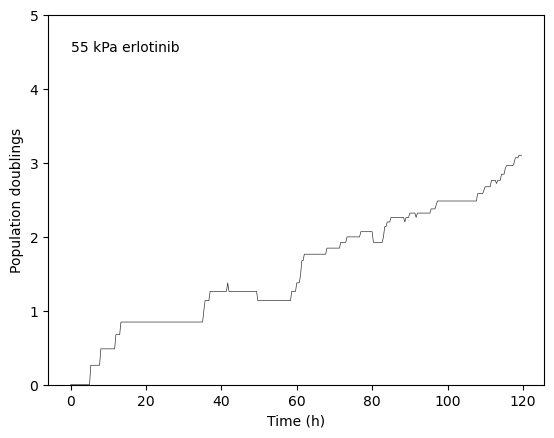

In [14]:
fig, ax = make_fig(cell_count, run_time, title=condition)
add_plot(cell_count, run_time, fig, ax, title=condition)

Empty DataFrame
Columns: [Starting cell, End_of_Expt, Death, Birthtime, Lifespan]
Index: []
{'Starting cell': True, 'End_of_Expt': False, 'Death': False, 'Birthtime': 0, 'Lifespan': 13.14381270903}
  Starting cell End_of_Expt  Death   Birthtime   Lifespan
0          True       False  False           0  13.143813
1         False       False  False   13.143813  27.792642
2         False       False   True   40.936455   0.702341
3          True       False  False           0   7.826087
4         False       False  False    7.826087  25.083612
5         False       False  False   32.909699  29.698997
6         False       False  False   62.608696  22.073579
7         False       False  False   84.682274  30.501672
8         False        True  False  115.183946   4.715719
{'Starting cell': True, 'End_of_Expt': False, 'Death': False, 'Birthtime': 0, 'Lifespan': 5.117056856187}


(0.0, 125.0)

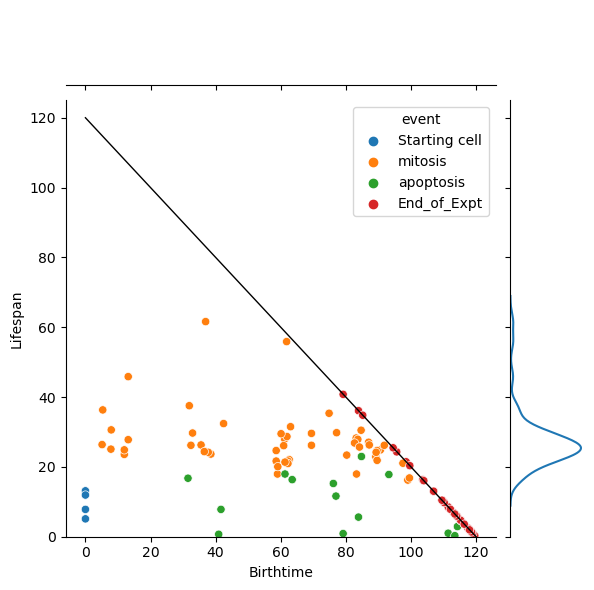

In [15]:
IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
all_events_simulated = call_events(run_time, IMT_eoe_counts) #Gives all events (apoptosis, mitosis, quiescence) and when they happen

#plot the results
grid = sns.JointGrid(x='Birthtime', y='Lifespan', data=all_events_simulated) #x axis = birthtime of a cell, y = endtime of this cell
g = grid.plot_joint(sns.scatterplot, hue='event', data=all_events_simulated) 
g.ax_joint.plot([run_time, 0], [0, run_time], 'b-', linewidth = 1, color='black') #Recorded events behind this line
sns.kdeplot(all_events_simulated.loc[all_events_simulated['event']=='mitosis', 'Lifespan'].to_list(), 
            ax=g.ax_marg_y, vertical=True, legend=False, bw=0.3) #output distribution of intermitotic times
plt.ylim(0, 125)

In [16]:
all_events_simulated

,event,Birthtime,Lifespan
0,Starting cell,0,13.143813
1,mitosis,13.143813,27.792642
2,apoptosis,40.936455,0.702341
3,Starting cell,0,7.826087
4,mitosis,7.826087,25.083612
...,...,...,...
113,End_of_Expt,112.125409,7.854523
114,End_of_Expt,114.050471,5.927539
115,End_of_Expt,110.210162,9.771928
116,End_of_Expt,109.524519,10.459952


Empty DataFrame
Columns: [Starting cell, End_of_Expt, Death, Birthtime, Lifespan]
Index: []
{'Starting cell': True, 'End_of_Expt': False, 'Death': False, 'Birthtime': 0, 'Lifespan': 13.14381270903}
  Starting cell End_of_Expt  Death   Birthtime   Lifespan
0          True       False  False           0  13.143813
1         False       False  False   13.143813  27.792642
2         False       False   True   40.936455   0.702341
3          True       False  False           0   7.826087
4         False       False  False    7.826087  25.083612
5         False       False  False   32.909699  29.698997
6         False       False  False   62.608696  22.073579
7         False       False  False   84.682274  30.501672
8         False        True  False  115.183946   4.715719
{'Starting cell': True, 'End_of_Expt': False, 'Death': False, 'Birthtime': 0, 'Lifespan': 5.117056856187}


(0.0, 125.0)

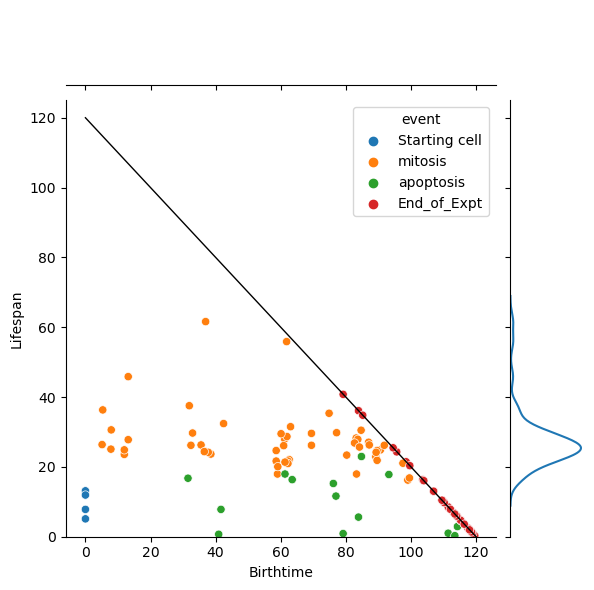

In [17]:
IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
all_events_simulated = call_events(run_time, IMT_eoe_counts) #Gives all events (apoptosis, mitosis, quiescence) and when they happen

#plot the results
grid = sns.JointGrid(x='Birthtime', y='Lifespan', data=all_events_simulated) #x axis = birthtime of a cell, y = endtime of this cell
g = grid.plot_joint(sns.scatterplot, hue='event', data=all_events_simulated) 
g.ax_joint.plot([run_time, 0], [0, run_time], 'b-', linewidth = 1, color='black') #Recorded events behind this line
sns.kdeplot(all_events_simulated.loc[all_events_simulated['event']=='mitosis', 'Lifespan'].to_list(), 
            ax=g.ax_marg_y, vertical=True, legend=False, bw=0.3) #output distribution of intermitotic times
plt.ylim(0, 125)

In [18]:
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

In [19]:
condition = "55 kPa erlotinib"

In [20]:
start_time = datetime.datetime.now()

conditions = ['4 kPa erlotinib', '4 kPa DMSO', '55 kPa erlotinib', '55 kPa DMSO']

for condition in conditions:
    for num in range(3):
        init = 5
        
        fn_cellcount = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')
        fn_cells = Path(SAVE_DIR, f'cells_{condition}_{num}_param_orig.csv')
        
        if OVERWRITE or not os.path.exists(fn_cellcount) or not os.path.exists(fn_cells):
            (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, 
                                                                                   model, ECM_conditions, condition, 
                                                                                   sampled_parameter_names, thr=[0.26, 0.14], 
                                                                                   return_plot=False, bypass=True)

            print(f"Saving to {fn_cellcount}...")
            np.savetxt(fn_cellcount, cell_count, delimiter=',')
            print(f"Saving to {fn_cells}...")
            with open(fn_cells, 'wb') as f:
                pickle.dump(cells, f, protocol=pickle.HIGHEST_PROTOCOL)
        else:
            print(f"File {fn_cellcount} and {fn_cells} already exist. Skipping...")
            
        current_time = datetime.datetime.now()
        print(f'elapsed time is {(current_time-start_time)/60} minutes')

File /Users/darren/ECM_mod_output/cellcount_4 kPa erlotinib_0_param_orig.csv and /Users/darren/ECM_mod_output/cells_4 kPa erlotinib_0_param_orig.csv already exist. Skipping...
elapsed time is 0:00:00.000009 minutes
File /Users/darren/ECM_mod_output/cellcount_4 kPa erlotinib_1_param_orig.csv and /Users/darren/ECM_mod_output/cells_4 kPa erlotinib_1_param_orig.csv already exist. Skipping...
elapsed time is 0:00:00.000015 minutes
File /Users/darren/ECM_mod_output/cellcount_4 kPa erlotinib_2_param_orig.csv and /Users/darren/ECM_mod_output/cells_4 kPa erlotinib_2_param_orig.csv already exist. Skipping...
elapsed time is 0:00:00.000016 minutes
File /Users/darren/ECM_mod_output/cellcount_4 kPa DMSO_0_param_orig.csv and /Users/darren/ECM_mod_output/cells_4 kPa DMSO_0_param_orig.csv already exist. Skipping...
elapsed time is 0:00:00.000016 minutes
File /Users/darren/ECM_mod_output/cellcount_4 kPa DMSO_1_param_orig.csv and /Users/darren/ECM_mod_output/cells_4 kPa DMSO_1_param_orig.csv already exi

In [21]:
conditions = ['0.6 kPa erlotinib', '0.6 kPa DMSO']

for condition in conditions:
    for num in range(3):
        init = 10
        
        fn_cellcount = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')
        fn_cells = Path(SAVE_DIR, f'cells_{condition}_{num}_param_orig.csv')

        if OVERWRITE or not os.path.exists(fn_cellcount) or not os.path.exists(fn_cells):
            (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, 
                                                                                   model, ECM_conditions, condition, 
                                                                                   sampled_parameter_names, thr=[0.26, 0.14], 
                                                                                   return_plot=False, bypass=True)
            print(f"Saving to {fn_cellcount}...")
            np.savetxt(fn_cellcount, cell_count, delimiter=',')
            print(f"Saving to {fn_cells}...")
            with open(fn_cells, 'wb') as f:
                pickle.dump(cells, f, protocol=pickle.HIGHEST_PROTOCOL)
        else:
            print(f"File {fn_cellcount} and {fn_cells} already exist. Skipping...")
            
        current_time = datetime.datetime.now()
        print(f'elapsed time is {(current_time-start_time)/60} minutes')

File /Users/darren/ECM_mod_output/cellcount_0.6 kPa erlotinib_0_param_orig.csv and /Users/darren/ECM_mod_output/cells_0.6 kPa erlotinib_0_param_orig.csv already exist. Skipping...
elapsed time is 0:00:00.000128 minutes
File /Users/darren/ECM_mod_output/cellcount_0.6 kPa erlotinib_1_param_orig.csv and /Users/darren/ECM_mod_output/cells_0.6 kPa erlotinib_1_param_orig.csv already exist. Skipping...
elapsed time is 0:00:00.000131 minutes
File /Users/darren/ECM_mod_output/cellcount_0.6 kPa erlotinib_2_param_orig.csv and /Users/darren/ECM_mod_output/cells_0.6 kPa erlotinib_2_param_orig.csv already exist. Skipping...
elapsed time is 0:00:00.000134 minutes
File /Users/darren/ECM_mod_output/cellcount_0.6 kPa DMSO_0_param_orig.csv and /Users/darren/ECM_mod_output/cells_0.6 kPa DMSO_0_param_orig.csv already exist. Skipping...
elapsed time is 0:00:00.000136 minutes
File /Users/darren/ECM_mod_output/cellcount_0.6 kPa DMSO_1_param_orig.csv and /Users/darren/ECM_mod_output/cells_0.6 kPa DMSO_1_param_

In [22]:
conditions = ['0.6 kPa erlotinib', '0.6 kPa DMSO', '4 kPa erlotinib', '4 kPa DMSO', '55 kPa erlotinib', '55 kPa DMSO']

for condition in conditions:
    runIMTs(20, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, 200, 'no_inhib',
            SAVE_DIR)

0.6 kPa erlotinib
BAXm_0
BCL2_0
  Starting cell End_of_Expt  Death  Birthtime   Lifespan
0         False       False  False          0  46.755853
1         False        True  False  46.755853  73.143813
2         False       False  False          0  24.682274
3         False       False   True  24.682274  40.535117
{'Starting cell': True, 'End_of_Expt': False, 'Death': False, 'Birthtime': 0, 'Lifespan': 7.826086956522}
   Starting cell End_of_Expt  Death  Birthtime    Lifespan
0          False       False  False          0   46.755853
1          False        True  False  46.755853   73.143813
2          False       False  False          0   24.682274
3          False       False   True  24.682274   40.535117
4           True       False  False          0    7.826087
5          False       False  False   7.826087   40.535117
6          False       False   True  48.361204    8.628763
7           True       False  False          0    9.732441
8          False       False  False   9.732441